# Estado del arte: lo que midió la literatura y lo que omiten las herramientas

- **Nivel:** 3, Estado del arte
- **Requisitos previos:** los cuadernos 02 a 06 de este tema (las mediciones con que se compara la literatura)
- **Tiempo de lectura:** unos 55 minutos

## Objetivos

Al terminar este cuaderno puedes:

- nombrar los tres estudios de simulación publicados sobre el tamaño y la potencia de pruebas de validación (documento de trabajo 14 de BCBS, Yurdakul y Naranjo, Demler et al.), decir qué midió cada uno, y leer cómo se comparan celda por celda las repeticiones del motor con ellos;
- contrastar cada veredicto que da la literatura sobre una prueba (la prueba binomial bajo correlación, la prueba normal, las reglas empíricas del PSI, DeLong en modelos anidados, los grados de libertad de Hosmer-Lemeshow) con la medición de los artefactos versionados, y decir dónde el veredicto se cumple y dónde necesita una salvedad;
- decir qué cubren las herramientas de validación de la investigación del producto y qué omiten: las pruebas del BCE, y cualquier tamaño o potencia medidos.

## Preparación

Instala una vez el entorno fijado, en un entorno virtual, con el comando de siempre:

```bash
pip install -r notebooks/requirements.txt
```

o solo los paquetes que usa este cuaderno, con las mismas versiones exactas:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` en Windows) construye `.venv-notebooks` por ti. La celda siguiente importa los paquetes e imprime sus versiones.

In [1]:
# Importar las herramientas e imprimir las versiones con que corren, para compararlas con notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv
from scipy import stats

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.9.0
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Datos

Los datos son los artefactos versionados del caso C22 (validar al validador), calculados con generadores de verdad conocida de `riskvalidation.generators` (licencia MIT, clase `generated`). Tres de ellos llevan, en `outputs.golden`, un estudio de simulación publicado repetido celda por celda: la tasa publicada de cada celda, la tasa que midió el motor y la diferencia estandarizada. Las tasas publicadas son números citados de los artículos (solo derivadas).

- **Archivos que se leen:** `data/derived/C22/clustering.json` (documento de trabajo 14 de BCBS, Tablas 7 y 8, 144 celdas) y sus simulaciones; `drift.json` (Yurdakul y Naranjo, Tabla 4, 54 celdas); `leakage.json` (Demler et al., una celda); y `null.json` para las filas de Hosmer-Lemeshow.
- **La literatura misma** se cita desde los dossiers de investigación del producto (`wip/contraste/12-u3-size-power-and-generators` secciones 2 a 6, y `06-model-risk-management-and-validation` secciones C y D, en los registros de CAOS_MANAGE), que leyeron cada artículo el 2026-10-04 y el 2026-10-05. Las citas textuales de abajo, traducidas del inglés, vienen de esas lecturas, con número de página donde el dossier lo registra.

La celda siguiente carga los cuatro artefactos e imprime la versión del motor que los calculó.

In [2]:
# Cargar los cuatro artefactos de la comparación e imprimir la versión del motor que los calculó
LANG = "es"
ROOT = Path("../../..").resolve()
files = ("clustering", "drift", "leakage", "null")
artifacts = {name: json.loads((ROOT / "data" / "derived" / "C22" / f"{name}.json").read_text(encoding="utf-8")) for name in files}
rows = {name: {row["key"]: row for row in art["outputs"]["simulations"]} for name, art in artifacts.items()}
clustering, drift, leakage, null = (artifacts[name] for name in files)

for name in files:
    print(f"{name:11s} calculado por riskvalidation {artifacts[name]['provenance']['riskvalidation_version']} | {len(rows[name]):2d} simulaciones")
print("instalado:", rv.__version__)

clustering  calculado por riskvalidation 0.4.3 | 48 simulaciones
drift       calculado por riskvalidation 0.4.3 | 30 simulaciones
leakage     calculado por riskvalidation 0.4.3 | 14 simulaciones
null        calculado por riskvalidation 0.4.3 | 28 simulaciones
instalado: 0.9.0


## Método

Una repetición de un estudio de simulación publicado se compara con el artículo celda por celda. La tasa del artículo $r_\text{pub}$ viene de $n_\text{pub}$ corridas y la nuestra, $\hat r$, de $n$ corridas; ambas estiman una misma tasa verdadera, así que su diferencia tiene varianza $\bar r(1-\bar r)(1/n + 1/n_\text{pub})$ a la tasa agrupada $\bar r$, y una celda concuerda cuando la diferencia estandarizada cumple $|z| \le 3{,}29$ (bilateral 0,1%, porque el estudio hace muchas comparaciones). La función `agrees_with_published` del motor la calcula (Morris, White y Crowther, 2019, para el error de Monte Carlo de cada tasa).

Este cuaderno va más allá de contar concordancias: para cada veredicto que da la literatura sobre una prueba, lo evalúa sobre las mediciones versionadas y dice si se cumple, se cumple con una salvedad, o no se cumple. El primer paso tabula las celdas publicadas de los tres estudios.

### Paso 1: tres estudios publicados, cada celda recalculada

La celda siguiente recalcula la diferencia estandarizada de cada celda publicada de los tres estudios desde la tasa medida versionada y la publicada, cuenta las concordancias, y dibuja la tasa medida frente a la publicada para todas las celdas. Las celdas cerca de la diagonal concuerdan; la que no concuerda queda marcada.

BCBS WP14 Tablas 7 y 8: las pruebas normal y de semáforo               |  25000 corridas | 143 de 144 concuerdan | versionado 143 | z medio -0.112
Yurdakul y Naranjo (2020) Tabla 4: las reglas y la referencia del PSI  |  10000 corridas |  50 de  54 concuerdan | versionado 50 | z medio +0.666
Demler, Pencina y D'Agostino (2012): DeLong en modelos anidados        |   1000 corridas |   1 de   1 concuerdan | versionado 1 | z medio +0.578
todas las celdas: 194 de 199


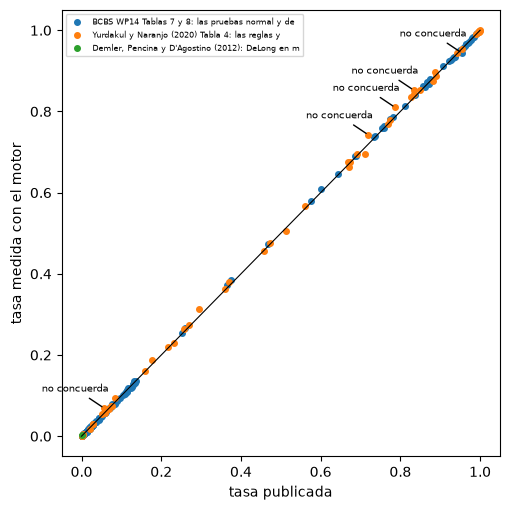

In [3]:
# Recalcular cada celda publicada de los tres estudios con agrees_with_published y dibujar lo medido frente a lo publicado
from riskvalidation.harness import Rate, agrees_with_published

fig, ax = plt.subplots(figsize=(5.2, 5.2))
total_cells = total_agree = 0
for index, name in enumerate(("clustering", "drift", "leakage")):
    study = artifacts[name]["outputs"]["golden"][0]
    n_runs = study["runs"]
    published, measured, agree, z_values = [], [], 0, []
    for cell in study["cells"]:
        ok, z = agrees_with_published(Rate(round(cell["measured"] * n_runs), n_runs), cell["published"], study["runs_published"])
        agree += ok
        z_values.append(z)
        published.append(cell["published"])
        measured.append(cell["measured"])
        if not ok:
            ax.annotate("no concuerda", (cell["published"], cell["measured"]), fontsize=7, xytext=(-45, 12), textcoords="offset points", arrowprops={"arrowstyle": "-"})
    ax.plot(published, measured, "o", markersize=4, color=f"C{index}", label=study["title"][LANG][:48])
    total_cells += len(study["cells"])
    total_agree += agree
    print(f"{study['title'][LANG][:70]:70s} | {study['runs_published']:6d} corridas | {agree:3d} de {len(study['cells']):3d} concuerdan | versionado {study['agree']} | z medio {np.mean(z_values):+.3f}")
print("todas las celdas:", total_agree, "de", total_cells)
ax.plot([0, 1], [0, 1], color="black", linewidth=0.8)
ax.set_xlabel("tasa publicada")
ax.set_ylabel("tasa medida con el motor")
ax.legend(fontsize=6, loc="upper left")
fig.tight_layout()
plt.show()

## Estado del arte

### Documento de trabajo 14 de BCBS (2005): las pruebas de calibración

El documento de trabajo 14 del Comité de Basilea (Studies on the validation of internal rating systems, revisado, mayo de 2005) evalúa las pruebas de calibración y corre un estudio de simulación de dos de ellas. Sus veredictos (páginas 41 y 42, traducidos del inglés):

- **Prueba binomial:** «Ejemplos del apéndice muestran que el error de tipo I verdadero (es decir, la probabilidad de rechazar erróneamente la hipótesis de un pronóstico de PD adecuado) puede ser mucho mayor que el nivel nominal de la prueba si los eventos de incumplimiento están correlacionados». Tomar en cuenta la dependencia «rinde pruebas de potencia bastante moderada, incluso con niveles bajos de correlación».
- **Prueba normal:** «Los estudios de simulación muestran que la calidad de la aproximación normal es moderada pero exhibe un sesgo conservador. En consecuencia, el error de tipo I verdadero tiende a ser menor que el nivel nominal de la prueba».
- **Conclusión:** «en la actualidad no hay pruebas realmente potentes de calibración adecuada. Por los efectos de correlación que deben respetarse, incluso parece no haber manera de desarrollar tales pruebas».

El apéndice imprime valores críticos de la prueba binomial para una PD de 1%, 1.000 deudores y una confianza de 99% (Ejemplo 3): 19 incumplimientos cuando los incumplimientos son independientes, y 35, 49, 63 y 77 cuando la correlación de activos es 5%, 10%, 15% y 20% (dossier 12, sección 2.2). La primera verificación los recalcula con el motor y calcula el tamaño verdadero que implican.

### Paso 2: la prueba binomial bajo correlación

`critical_count` encuentra el menor conteo de incumplimientos en que rechaza una prueba registrada. Con `pd.binomial` al nivel de 1% da el valor crítico independiente, y con `pd.binomial_vasicek` con una correlación supuesta da el valor crítico de la prueba corregida. `rejection_probability` da luego el tamaño verdadero de la prueba independiente (la prueba de 99% del artículo) cuando los incumplimientos siguen esa correlación.

In [4]:
# Conteos críticos de la prueba binomial independiente y con corrección de Vasicek al 99%, y tamaño verdadero de la prueba independiente bajo correlación
from riskvalidation.harness import critical_count, rejection_probability

print(f"{'correlación de activos':>18s} {'k* corregido':>13s} {'k* independiente':>15s} {'tamaño verdadero de la independiente':>38s}")
independent_k = critical_count("pd.binomial", 1000, 0.01, 0.01)
print(f"{0.0:18.2f} {independent_k:13d} {independent_k:15d} {rejection_probability('pd.binomial', 1000, 0.01, 0.01)['probability']:38.4f}")
for rho in (0.05, 0.10, 0.15, 0.20):
    corrected_k = critical_count("pd.binomial_vasicek", 1000, 0.01, 0.01, rho=rho)
    size = rejection_probability("pd.binomial", 1000, 0.01, 0.01, rho_true=rho)["probability"]
    print(f"{rho:18.2f} {corrected_k:13d} {independent_k:15d} {size:38.4f}")

correlación de activos  k* corregido k* independiente   tamaño verdadero de la independiente
              0.00            19              19                                 0.0069
              0.05            35              19                                 0.1113
              0.10            49              19                                 0.1441
              0.15            63              19                                 0.1539
              0.20            77              19                                 0.1549


### Paso 3: el veredicto sobre la prueba normal

WP14 dice que la prueba normal «exhibe un sesgo conservador», con un error de tipo I verdadero que «tiende a ser menor que el nivel nominal». La propia Tabla 7 del artículo reporta el error de tipo I al 5% en ocho escenarios, cuatro con años independientes (`I_`) y cuatro con dependencia (`DC_`, `DV_`). La celda siguiente lee las tasas publicadas al 5% desde el artefacto, cuenta cuántas quedan sobre 5% en cada grupo, e imprime el tamaño que midió el motor en la escalera de agrupamiento, donde la correlación de factor entre años es 0,2 siempre que la correlación de activos es positiva.

In [5]:
# Contar los errores de tipo I publicados de la prueba normal sobre 5% por grupo e imprimir el tamaño medido a lo largo de la escalera de agrupamiento
study = clustering["outputs"]["golden"][0]
published_normal = {c["row"]: c["published"] for c in study["cells"] if c["table"] == "Table 7" and c["column"] == "0.05" and "normal" in c["row"]}
for group, prefix in (("años independientes", "I_"), ("años dependientes", "D")):
    chosen = {name: rate for name, rate in published_normal.items() if name.startswith(prefix)}
    above = sum(rate > 0.05 for rate in chosen.values())
    print(f"{group:20s} tasas publicadas al 5%: {sorted(chosen.values())} | sobre 5%: {above} de {len(chosen)}")

ladder = clustering["outputs"]["ladder"]["values"]
measured = [rows["clustering"][f"pd.normal_multiperiod@rho{rho:g}"]["rates"]["p<0.05"]["rate"] for rho in ladder]
print("tamaño medido, según la correlación de activos", {rho: round(float(rate), 4) for rho, rate in zip(ladder, measured)})

años independientes  tasas publicadas al 5%: [0.059, 0.059, 0.077, 0.081] | sobre 5%: 4 de 4
años dependientes    tasas publicadas al 5%: [0.037, 0.049, 0.062, 0.07] | sobre 5%: 2 de 4
tamaño medido, según la correlación de activos {0.0: 0.082, 0.02: 0.0905, 0.05: 0.074, 0.1: 0.0515, 0.15: 0.0455, 0.2: 0.035}


### Paso 4: «no hay pruebas realmente potentes»

La conclusión del artículo es sobre pruebas de calibración con incumplimientos correlacionados. La probabilidad de rechazo exacta de la prueba binomial con corrección de Vasicek, que es la propia respuesta del artículo a la correlación, se puede calcular cuando la correlación verdadera es igual a la supuesta. La celda siguiente calcula su potencia al 5%, para 1.000 deudores con una PD de 1%, cuando la PD verdadera sube a 1,25, 1,5, 2 y 3 veces la PD aplicada, para una correlación de activos de 5% (baja) y de 12%, e imprime la potencia de la prueba binomial sin corregir junto a ella con su tamaño en $k = 1$, que dice si esa potencia se compra con falsas alarmas.

In [6]:
# Potencia exacta de la prueba binomial corregida y sin corregir con incumplimientos correlacionados, n = 1000, PD = 1%
factors = (1.0, 1.25, 1.5, 2.0, 3.0)
print(f"{'correlación':>11s} {'prueba':>13s} " + " ".join(f"{'k = ' + str(k):>8s}" for k in factors) + f"   ({'potencia al 5%; k = 1 es el tamaño'})")
for rho in (0.05, 0.12):
    corrected = [rejection_probability("pd.binomial_vasicek", 1000, 0.01, 0.05, pd_true=0.01 * k, rho_true=rho, rho=rho)["probability"] for k in factors]
    plain = [rejection_probability("pd.binomial", 1000, 0.01, 0.05, pd_true=0.01 * k, rho_true=rho)["probability"] for k in factors]
    print(f"{rho:11.2f} {'corregida':>13s} " + " ".join(f"{p:8.3f}" for p in corrected))
    print(f"{rho:11.2f} {'sin corregir':>13s} " + " ".join(f"{p:8.3f}" for p in plain))

correlación        prueba  k = 1.0 k = 1.25  k = 1.5  k = 2.0  k = 3.0   (potencia al 5%; k = 1 es el tamaño)
       0.05     corregida    0.043    0.087    0.145    0.284    0.561
       0.05  sin corregir    0.178    0.282    0.388    0.576    0.816
       0.12     corregida    0.050    0.080    0.114    0.190    0.349
       0.12  sin corregir    0.198    0.270    0.340    0.465    0.653


### Yurdakul y Naranjo (2020): el PSI

Yurdakul y Naranjo (Statistical properties of the population stability index, Journal of Risk Model Validation 14(4)) parten de la observación de que las bandas del PSI de 0,10 y 0,25 se «usan sin referencia a tasas de error estadístico de tipo I o de tipo II». Derivan la distribución muestral del índice (su Teorema 3.3), proponen la referencia $(1/n + 1/m)\,\chi^2_{1-\alpha,\,B-1}$ e informan una simulación (Tabla 4) con 10.000 corridas. Su lectura (traducida del inglés): «la tasa de error de tipo I para PSI > 0,10 es demasiado grande, salvo cuando ambos tamaños de muestra superan 400. En cambio, la tasa de error de tipo I para PSI > 0,25 es demasiado pequeña cuando ambos tamaños de muestra superan 200, de modo que la prueba es demasiado conservadora. La referencia chi-cuadrado mantiene un error de tipo I razonable, cercano a $\alpha$ = 0,05 [...] las pruebas PSI > 0,10 y PSI > 0,25 tienen potencias que en realidad disminuyen con el tamaño de muestra».

### Paso 5: los cuatro hallazgos, sobre la Tabla 4

Las celdas del artefacto permiten leer cada hallazgo. La celda siguiente toma las filas con muestras iguales ($m = n$ = 100, 200, 400) e imprime, para las columnas sin desplazamiento (error de tipo I) y las de un cuarto de desviación estándar (potencia), la tasa publicada y la medida de las dos reglas y de la referencia, y luego revisa la dirección de cada hallazgo sobre las tasas medidas.

In [7]:
# Imprimir las tasas publicadas y medidas de las dos reglas y de la referencia para muestras iguales y revisar la dirección de cada hallazgo
from functools import reduce

GLOSSARY = (("Table", "Tabla"), ("traffic", "semáforo"), ("shift", "desplazamiento"), (" SD", " DE"), ("chi-square", "chi-cuadrado"), ("section", "sección"), ("nested", "anidados"))
gloss = lambda text: reduce(lambda acc, pair: acc.replace(*pair), GLOSSARY, text)
yn = drift["outputs"]["golden"][0]["cells"]
sizes = ("m 100, n 100", "m 200, n 200", "m 400, n 400")
columns = ("PSI > 0.10", "PSI > 0.25", "chi-square")
measured = {}
for shift in ("0", "0.25"):
    print("desplazamiento", shift, "DE", "(publicada / medida)")
    for size in sizes:
        cells = {c["column"]: c for c in yn if c["row"] == size}
        parts = []
        for column in columns:
            c = cells[f"shift {shift} SD, {column}"]
            measured[(shift, size, column)] = c["measured"]
            parts.append(f"{c['published']:.3f} / {c['measured']:.4f}")
        print(f"  {size:14s} " + " | ".join(f"{gloss(col)}: {part}" for col, part in zip(columns, parts)))

rule10 = [measured[("0", s, "PSI > 0.10")] for s in sizes]
rule25 = [measured[("0", s, "PSI > 0.25")] for s in sizes]
chi = [measured[("0", s, "chi-square")] for s in sizes]
print("el error de tipo I de la regla 0.10 baja de 5% solo con 400:", [round(r, 3) for r in rule10], ["sí" if r < 0.05 else "no" for r in rule10])
print("el error de tipo I de la regla 0.25 queda muy bajo 5% sobre 200:", [round(r, 4) for r in rule25])
print("la referencia chi-cuadrado se mantiene entre", round(min(chi), 4), "y", round(max(chi), 4))
for column in columns[:2]:
    power = [measured[("0.25", s, column)] for s in sizes]
    print(f"{'potencia de'} {column} {'con el tamaño de muestra:'} {[round(p, 3) for p in power]} | {'disminuye:'} {'sí' if power[0] > power[1] > power[2] else 'no'}")
power_chi = [measured[("0.25", s, "chi-square")] for s in sizes]
print("potencia de la referencia chi-cuadrado con el tamaño de muestra:", [round(p, 3) for p in power_chi], "|", "aumenta:", ("sí" if power_chi[0] < power_chi[1] < power_chi[2] else "no"))

desplazamiento 0 DE (publicada / medida)
  m 100, n 100   PSI > 0.10: 0.849 / 0.8525 | PSI > 0.25: 0.233 / 0.2284 | chi-cuadrado: 0.076 / 0.0753
  m 200, n 200   PSI > 0.10: 0.369 / 0.3807 | PSI > 0.25: 0.004 / 0.0043 | chi-cuadrado: 0.057 / 0.0688
  m 400, n 400   PSI > 0.10: 0.020 / 0.0186 | PSI > 0.25: 0.000 / 0.0000 | chi-cuadrado: 0.051 / 0.0555
desplazamiento 0.25 DE (publicada / medida)
  m 100, n 100   PSI > 0.10: 0.943 / 0.9429 | PSI > 0.25: 0.459 / 0.4570 | chi-cuadrado: 0.218 / 0.2198
  m 200, n 200   PSI > 0.10: 0.775 / 0.7787 | PSI > 0.25: 0.085 / 0.0934 | chi-cuadrado: 0.360 / 0.3623
  m 400, n 400   PSI > 0.10: 0.513 / 0.5064 | PSI > 0.25: 0.004 / 0.0032 | chi-cuadrado: 0.671 / 0.6638
el error de tipo I de la regla 0.10 baja de 5% solo con 400: [0.853, 0.381, 0.019] ['no', 'no', 'sí']
el error de tipo I de la regla 0.25 queda muy bajo 5% sobre 200: [0.2284, 0.0043, 0.0]
la referencia chi-cuadrado se mantiene entre 0.0555 y 0.0753
potencia de PSI > 0.10 con el tamaño de m

### Demler, Pencina y D'Agostino (2012): DeLong en modelos anidados

Demler et al. (Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23)) muestran que la prueba de DeLong, derivada para modelos con parámetros conocidos, es conservadora cuando compara dos modelos ajustados con los mismos datos y el mayor agrega un predictor sin efecto. Su simulación, con datos tipo Framingham y 1.000 repeticiones, encontró (traducido del inglés): «el nivel de significancia de la prueba F es cercano al nivel nominal de 0,05, mientras que es 0,001 para la prueba de DeLong».

### Paso 6: la única celda publicada

`leakage.json` guarda esa celda: la tasa publicada (0,001), la tasa del motor sobre el mismo diseño y la diferencia estandarizada. La celda siguiente la imprime, con la tasa que midió el motor para la comparación no anidada sobre una muestra independiente, donde el artículo no encuentra problema.

In [8]:
# Imprimir la celda publicada de Demler, la tasa del motor y la comparación no anidada
study = leakage["outputs"]["golden"][0]
cell = study["cells"][0]
print(gloss(cell["table"]), "|", gloss(cell["row"]), "|", "nivel", cell["column"], "|", "publicada", cell["published"], "|", "medida", cell["measured"], "| z", round(cell["z"], 2), "|", "concuerda:", ("sí" if cell["agrees"] else "no"))
non_nested = rows["leakage"]["disc.delong@non-nested"]["rates"]["p<0.05"]
print("puntajes no anidados sobre una muestra independiente:", round(non_nested["rate"], 4), "(SE", round(non_nested["se"], 4), ")")

sección 2.3 | DeLong, anidados | nivel 0.05 | publicada 0.001 | medida 0.002 | z 0.58 | concuerda: sí
puntajes no anidados sobre una muestra independiente: 0.0525 (SE 0.005 )


### Hosmer y Lemeshow (1980): los grados de libertad

El estadístico de Hosmer-Lemeshow agrupa a los deudores por riesgo predicho. Su distribución de referencia original es $\chi^2_{G-2}$, para un modelo ajustado con los mismos datos. BCBS WP14 sostiene para PD dadas que la brecha estandarizada de cada grupo es asintóticamente un $\chi^2_1$ independiente, de modo que el estadístico sobre $G$ grupos es $\chi^2_G$ (página 60, para su prueba por grados). La literatura que leyó el dossier no da una regla explícita para muestras de validación («grados de libertad declarados desde el resultado estándar, artículo no releído», dossier 06), y las herramientas no son consistentes al respecto.

### Paso 7: qué hace cada elección sobre una muestra de validación

La celda siguiente calcula, con SciPy, el tamaño que un umbral de $G-2$ da a un estadístico $\chi^2_G$ y lo pone junto a las dos filas versionadas de la familia `null`: el motor con $G$ grados de libertad (el valor por defecto para PD dadas) y con $G-2$ (`fitted=True`).

In [9]:
# Tamaño de un umbral G-2 sobre un estadístico chi-cuadrado(G) junto a las filas versionadas de Hosmer-Lemeshow
for alpha, rule in ((0.05, "p<0.05"), (0.01, "p<0.01")):
    tail = stats.chi2.sf(stats.chi2.ppf(1 - alpha, 8), 10)
    given = rows["null"]["pd.hosmer_lemeshow@null"]["rates"][rule]
    fitted = rows["null"]["pd.hosmer_lemeshow@fitted"]["rates"][rule]
    print(f"nivel {alpha:.2f} | chi-cuadrado(10) más allá del umbral chi-cuadrado(8) {tail:.4f} | G-2: {fitted['rate']:.4f} ± {fitted['se']:.4f} | G: {given['rate']:.4f} ± {given['se']:.4f}")

nivel 0.05 | chi-cuadrado(10) más allá del umbral chi-cuadrado(8) 0.1146 | G-2: 0.1098 ± 0.0049 | G: 0.0460 ± 0.0033
nivel 0.01 | chi-cuadrado(10) más allá del umbral chi-cuadrado(8) 0.0284 | G-2: 0.0338 ± 0.0029 | G: 0.0097 ± 0.0016


### Las pruebas del BCE y las herramientas de validación

Las instrucciones del BCE para reportar resultados de validación (2019) definen los estadísticos y los valores p de las pruebas que implementa el motor (la prueba de Jeffreys, el AUC frente al AUC inicial, las pruebas de migración, la prueba de concentración). La investigación del producto (dossier 06, sección A.3) verificó por búsqueda de texto completo que el documento fija estadísticos y valores p y no fija umbrales de aprobación o rechazo, que son responsabilidad de la institución.

Las herramientas que la investigación revisó el 2026-10-04 (dossier 06, sección D, mediante las interfaces de GitHub y PyPI) ofrecen, entre otras:

| Herramienta | Qué lista su documentación | Licencia |
|---|---|---|
| PiML-Toolbox | pruebas de resultado: exactitud, explicabilidad, equidad, puntos débiles, sobreajuste, confiabilidad, robustez, resiliencia; reemplazada por MoDeVa | Apache-2.0 (MoDeVa propietaria) |
| ValidMind | pruebas de validación de datos y de modelo, incluidos PSI, KS, Gini y curvas de calibración, y deriva | AGPL-3.0 o comercial |
| BBVA mercury-robust y mercury-monitoring | pruebas de deriva, filtración de etiquetas, esquema y cohortes | Apache-2.0 |
| ING popmon | deriva: KS, chi-cuadrado, Jensen-Shannon, PSI; semáforos sobre desviaciones de 4 y 7 desviaciones estándar | MIT |
| Evidently | deriva: KS, chi-cuadrado, prueba z, Wasserstein, Jensen-Shannon, PSI, KL; calidad de datos; calidad de modelo | Apache-2.0 |
| NannyML | estimación del desempeño sin etiquetas, deriva univariada y multivariada | Apache-2.0 |
| deepchecks | suites de integridad de datos, validación entrenamiento-prueba y evaluación de modelos | AGPL-3.0 |
| alibi-detect | deriva: KS, MMD, LSDD, chi-cuadrado, basada en clasificador; valores atípicos | BSL 1.1 |

El dossier registra (líneas 1117 a 1121) que ninguna herramienta encontrada implementa exactamente como se especifica las pruebas del BCE de Jeffreys, MWB, z de migración, HHI-CV ni gAUC. Sus catálogos listan pruebas, umbrales y semáforos; el dossier no registró tamaño ni potencia medidos para ellos en los README y la documentación que leyó. Eso es una afirmación sobre lo que encontró la revisión, y NO VERIFICADA más allá de ella: la revisión no ejecutó las herramientas ni leyó su código.

## Resultados

- **El motor repite los tres estudios publicados: 194 de 199 celdas concuerdan.** El documento de trabajo 14 de BCBS da 143 de 144 (diferencia estandarizada media -0,11, de modo que el motor queda algo bajo el artículo), Yurdakul y Naranjo 50 de 54 (+0,67, algo sobre) y Demler et al. 1 de 1. Las cinco celdas que no concuerdan son la celda de semáforo de la Tabla 8 (cuaderno 04) y las cuatro celdas de la Tabla 4 (cuaderno 05). La figura muestra todas las celdas sobre o cerca de la diagonal, con la única celda lejana marcada.
- **El veredicto sobre la binomial se cumple, y los valores críticos del artículo se reproducen.** La prueba binomial corregida del motor da conteos críticos de 35, 49, 63 y 77 incumplimientos con correlaciones de activos de 5%, 10%, 15% y 20%, frente a 19 de la prueba independiente: los valores que imprime el artículo en su Ejemplo 3. La prueba independiente de 99%, que debería rechazar 1% de las veces, tiene un tamaño verdadero de 0,69% sin correlación y de 11,1%, 14,4%, 15,4% y 15,5% con ella. «Mucho mayor que el nivel nominal» es exacto.
- **El veredicto sobre la prueba normal necesita una salvedad.** WP14 dice que el error de tipo I verdadero «tiende a ser menor que el nivel nominal». Su propia Tabla 7 muestra la prueba normal sobre 5% en los cuatro escenarios independientes (5,9% a 8,1%) y en dos de cuatro dependientes, y el motor mide 8,2% con años independientes, 9,1% con correlación de activos de 2% y 7,4% con 5%. El tamaño llega al nivel nominal solo con dependencia fuerte (5,2% con 10%, 4,6% con 15%, 3,5% con 20%). El sesgo conservador es real para años fuertemente correlacionados; para una serie de cinco años la prueba sobrerrechaza, lo que el cuaderno 02 atribuye a un estadístico $t$ con cuatro grados de libertad.
- **«No hay pruebas realmente potentes» se cumple para incumplimientos correlacionados, con números.** La prueba binomial con corrección de Vasicek, con la correlación correcta, tiene una potencia de 8,7% cuando la PD está 25% baja y de 14,5% cuando está 50% baja con correlación de 5%, y de 56,1% cuando está tres veces baja; con 12% las cifras son 8,0%, 11,4% y 34,9%. La prueba sin corregir tiene más potencia (28,2% a 81,6% con 5%) solo porque su tamaño bajo esa correlación es 17,8%: la potencia se compra con falsas alarmas. Con incumplimientos independientes el cuadro cambia (cuaderno 03: 80% de potencia con una PD 26% baja). El pesimismo del artículo es sobre el agrupamiento, y el agrupamiento es lo que cuesta la potencia.
- **Los cuatro hallazgos de Yurdakul y Naranjo se reproducen en dirección.** La regla de 0,10 tiene un error de tipo I de 85,3%, 38,1% y 1,9% con 100, 200 y 400 por muestra, bajo 5% solo con 400; la regla de 0,25 22,8%, 0,4% y 0,0%; la referencia chi-cuadrado se mantiene entre 5,6% y 7,5%. La potencia de las dos reglas cae con el tamaño de muestra (94,3%, 77,9%, 50,6% y 45,7%, 9,3%, 0,3% con un desplazamiento de un cuarto de desviación estándar) mientras la de la referencia sube (22,0%, 36,2%, 66,4%). El desfase está declarado: la celda chi-cuadrado con 200 por muestra, 6,9% frente al 5,7% impreso, es una de las cuatro celdas que discrepan.
- **Demler et al. se reproducen.** La prueba de DeLong anidada rechazó 2 de 1.000, frente al 0,001 que reportan (z = 0,58); con puntajes no anidados de igual AUC y una muestra independiente rechaza 5,25% (EE 0,50 puntos), que es el caso donde el artículo no encuentra problema.
- **Los grados de libertad de Hosmer-Lemeshow no los resuelve la literatura que leyó la investigación, y la medición los resuelve para el motor.** Un umbral de $G-2$ sobre un estadístico $\chi^2_G$ rechazaría 11,5% al 5% y 2,8% al 1%; el motor con $G-2$ mide 11,0% y 3,4%, y con $G$ grados de libertad 4,6% y 1,0%.
- **Las herramientas omiten las pruebas del BCE y cualquier tasa de error medida, hasta donde llegó la revisión.** Las ocho herramientas revisadas listan pruebas de deriva, de desempeño y de robustez, algunas con umbrales por defecto o semáforos, y el dossier no registra ninguna que implemente como se especifica las pruebas del BCE de Jeffreys, MWB, z de migración, HHI-CV y gAUC, ni ninguna que publique un tamaño o potencia medidos. Eso es una afirmación sobre una revisión de documentación hecha el 2026-10-04, no sobre el código de las herramientas.

Lo que este cuaderno no muestra: los veredictos de estudios ajenos a las tres simulaciones y a la lectura del dossier (por ejemplo la literatura posterior sobre los grupos de Hosmer-Lemeshow), ni cómo se comportan las herramientas al ejecutarlas. Si la medición del cuaderno 08 va más allá de este estado del arte es su propia pregunta.

## Resumen

- La investigación tiene tres estudios de simulación publicados sobre el tamaño y la potencia de pruebas de validación (documento de trabajo 14 de BCBS, Yurdakul y Naranjo, Demler et al.), y el motor repite 194 de sus 199 celdas dentro del error de Monte Carlo.
- El veredicto de WP14 sobre la prueba binomial se cumple exactamente; su veredicto de que la prueba normal es conservadora se cumple solo con dependencia fuerte; su pesimismo sobre la potencia se cumple para incumplimientos correlacionados, con los números mostrados.
- Los cuatro hallazgos de Yurdakul y Naranjo sobre el PSI se reproducen en dirección, con un desfase declarado en cuatro celdas; el 0,001 de Demler et al. se reproduce como 2 de 1.000.
- La literatura que leyó la investigación no resuelve los grados de libertad de Hosmer-Lemeshow para PD dadas; la medición sí, a favor de $G$.
- Las herramientas revisadas listan pruebas y umbrales, no implementan ninguna de las pruebas del BCE como se especifica, y no registran tamaño ni potencia medidos, hasta donde llegó la revisión.

**Qué probar a continuación.** Cambia la correlación de activos del paso 4 a 0,20 y mira la potencia de la prueba corregida con los mismos factores; luego lee el cuaderno 08, que pone toda la medición frente a este estado del arte.

## Referencias

- BCBS (2005), Studies on the validation of internal rating systems, Working Paper 14 (revised): los veredictos sobre las pruebas de calibración (páginas 41 a 42), los ejemplos del apéndice sobre la prueba binomial, y la simulación de las pruebas normal y de semáforo (páginas 61 a 67). https://www.bis.org/publications/studies-validation-internal-rating-systems-revised.pdf
- Yurdakul, B. y Naranjo, J. (2020), Statistical properties of the population stability index, Journal of Risk Model Validation 14(4). https://doi.org/10.21314/JRMV.2020.227
- Demler, O. V., Pencina, M. J. y D'Agostino, R. B. Sr (2012), Misuse of DeLong test to compare AUCs for nested models, Statistics in Medicine 31(23). https://doi.org/10.1002/sim.5328
- Hosmer, D. W. y Lemeshow, S. (1980), Goodness of fit tests for the multiple logistic regression model, Communications in Statistics, Theory and Methods 9(10). https://doi.org/10.1080/03610928008827941
- ECB (2019), Instructions for reporting the validation results of internal models: IRB Pillar I models for credit risk. https://www.bankingsupervision.europa.eu/activities/internal_models/shared/pdf/instructions_validation_reporting_credit_risk.en.pdf
- Morris, T. P., White, I. R. y Crowther, M. J. (2019), Using simulation studies to evaluate statistical methods, Statistics in Medicine 38(11). https://doi.org/10.1002/sim.8086
- Los dossiers de investigación del producto (registros de CAOS_MANAGE, `wip/contraste/`): 06 (gestión del riesgo de modelo y validación, secciones A, C y D) y 12 (tamaño, potencia y generadores, secciones 1 a 6), leídos el 2026-10-04 y el 2026-10-05; y `docs/design/features/c22-validator/requirements.md` de este repositorio.